# Tugas 1 — Milestone 3: Analisis Temporal, Spasial, dan Advanced EDA

**Mata Kuliah:** Analisis Big Data  
**Target Check-in:** Pertemuan 8 (Mulai dikerjakan Pertemuan 6)  
**Nama Mahasiswa:** Rizqullah Atsir Dafa Childyasa Nusa
**NIM:** 202310370311119
**Username GitHub:**  dafanusa

---

## Panduan Pengerjaan Milestone 3:
1. **Sumber Data:** Gunakan dataset yang telah dibersihkan pada Milestone 2 (`02_data_cleaning.ipynb`).
2. **Analisis Temporal / Windowing:** Terapkan minimal satu operasi temporal (Polars `group_by_dynamic()`, `rolling_mean()`, `shift()`, atau DuckDB window function `OVER (...)`).
3. **Visualisasi Interaktif:** Bangun minimal 6 visualisasi interaktif informatif menggunakan Plotly Express / Graph Objects atau Altair.
4. **Perumusan Insight:** Tuliskan minimal 5 temuan atau wawasan analitik mendalam berdasarkan hasil visualisasi data di atas.


## Bagian 1: Inisialisasi dan Memuat Data Bersih

Muat dataset hasil pembersihan dari folder `data/` menggunakan Polars.

In [1]:
# ============================================================
# BAGIAN 1. INISIALISASI DAN MEMUAT DATA BERSIH
# ============================================================

from pathlib import Path
import warnings

import polars as pl
import duckdb
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from IPython.display import display, Markdown

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# 1. KONFIGURASI PATH PROYEK
# ------------------------------------------------------------

PROJECT_DIR = Path.cwd()

# Antisipasi jika notebook dijalankan dari folder notebooks/
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_PROCESSED = PROJECT_DIR / "data" / "processed"

PATH_PARQUET = (
    DATA_PROCESSED / "indonesian_religious_corpus_bersih.parquet"
)

PATH_PROFILING = (
    DATA_PROCESSED / "profiling_duckdb_summarize.csv"
)

# ------------------------------------------------------------
# 2. VALIDASI FILE
# ------------------------------------------------------------

if not PATH_PARQUET.exists():
    raise FileNotFoundError(
        f"Dataset Parquet tidak ditemukan: {PATH_PARQUET}\n"
        "Pastikan notebook dijalankan dari folder proyek "
        "'tugas1-abd-2026' dan notebook 02 sudah dijalankan."
    )

# ------------------------------------------------------------
# 3. MEMUAT DATASET HASIL CLEANING
# ------------------------------------------------------------

df = pl.read_parquet(PATH_PARQUET)

print("=" * 65)
print("ANALISIS BIG DATA - MILESTONE 3")
print("INDONESIAN RELIGIOUS CORPUS")
print("=" * 65)

print(f"\nJumlah baris : {df.height:,}")
print(f"Jumlah kolom : {df.width:,}")
print(f"Ukuran data  : {PATH_PARQUET.stat().st_size / (1024**2):.2f} MB")

print("\nDaftar kolom:")
print(df.columns)

print("\nTipe data:")
print(df.schema)

# ------------------------------------------------------------
# 4. PEMERIKSAAN DATA AWAL
# ------------------------------------------------------------

print("\nLima baris pertama:")
display(df.head(5))

print("\nRingkasan statistik:")
display(df.describe())

# ------------------------------------------------------------
# 5. PEMERIKSAAN DATA PROFILING
# ------------------------------------------------------------

if PATH_PROFILING.exists():
    print("\nRingkasan profiling DuckDB:")
    df_profiling = pl.read_csv(PATH_PROFILING)
    display(df_profiling.head(10))
else:
    print(
        "\nFile ringkasan profiling tidak ditemukan. "
        "Analisis tetap dapat dilanjutkan."
    )

# ------------------------------------------------------------
# 6. IDENTIFIKASI KOLOM BERDASARKAN NAMA
# ------------------------------------------------------------

columns_lower = {
    col.lower(): col
    for col in df.columns
}

def find_column(candidates):
    """
    Mencari kolom berdasarkan beberapa kemungkinan nama.
    Mengembalikan None jika tidak ditemukan.
    """
    for candidate in candidates:
        if candidate.lower() in columns_lower:
            return columns_lower[candidate.lower()]
    return None

TEXT_COL = find_column([
    "text", "content", "teks", "isi", "document",
    "dokumen", "sentence", "kalimat", "clean_text",
    "text_clean", "teks_bersih", "isi_teks"
])

DATE_COL = find_column([
    "date", "tanggal", "created_at", "timestamp",
    "published_at", "published_date", "waktu"
])

CATEGORY_COL = find_column([
    "category", "kategori", "religion", "agama",
    "topic", "topik", "label", "jenis"
])

SOURCE_COL = find_column([
    "source", "sumber", "source_name", "asal"
])

print("\n" + "=" * 65)
print("IDENTIFIKASI KOLOM")
print("=" * 65)

print("Kolom teks     :", TEXT_COL)
print("Kolom tanggal  :", DATE_COL)
print("Kolom kategori :", CATEGORY_COL)
print("Kolom sumber   :", SOURCE_COL)

if TEXT_COL is None:
    print(
        "\nPERHATIAN: Kolom teks belum teridentifikasi otomatis. "
        "Periksa nama kolom di atas dan sesuaikan TEXT_COL."
    )

print("\nBagian inisialisasi selesai.")

ANALISIS BIG DATA - MILESTONE 3
INDONESIAN RELIGIOUS CORPUS

Jumlah baris : 3,012,817
Jumlah kolom : 5
Ukuran data  : 120.88 MB

Daftar kolom:
['Label', 'Denomination', 'Location', 'Sentence_Unit', 'Link']

Tipe data:
Schema({'Label': String, 'Denomination': String, 'Location': String, 'Sentence_Unit': String, 'Link': String})

Lima baris pertama:


Label,Denomination,Location,Sentence_Unit,Link
str,str,str,str,str
"""Catholic""","""Katolisitas""","""National""","""Banyak orang yang bertanya-tan…","""https://katolisitas.org"""
"""Catholic""","""Katolisitas""","""National""","""Sebab ketika berselingkuh, ses…","""https://katolisitas.org"""
"""Catholic""","""Katolisitas""","""National""","""Kalian pengen masuk Surga ga?""","""https://katolisitas.org"""
"""Catholic""","""Katolisitas""","""National""","""Tinggallah bersama kami, ya Tu…","""https://katolisitas.org"""
"""Catholic""","""Katolisitas""","""National""","""Perjalanan dua orang murid ke …","""https://katolisitas.org"""



Ringkasan statistik:


statistic,Label,Denomination,Location,Sentence_Unit,Link
str,str,str,str,str,str
"""count""","""3012817""","""3012817""","""3012817""","""3012817""","""3012817"""
"""null_count""","""0""","""0""","""0""","""0""","""0"""
"""mean""",null,null,null,null,null
"""std""",null,null,null,null,null
"""min""","""Catholic""","""Alkitab SABDA""","""International""","""( (21): 87) Inilah tasbih Nabi…","""http://Www.muslimah.or.id"""
"""25%""",null,null,null,null,null
"""50%""",null,null,null,null,null
"""75%""",null,null,null,null,null
"""max""","""Protestant""","""Yufid""","""Sumatra""","""𝐅𝐫𝐚𝐧𝐬 𝐒𝐢𝐧𝐮𝐫𝐚𝐭Mengucapkan terim…","""https://zakat.ldii.or.id/zakat…"



Ringkasan profiling DuckDB:


column_name,column_type,min,max,approx_unique,avg,std,q25,q50,q75,count,null_percentage
str,str,str,str,i64,str,str,str,str,str,i64,f64
"""Label""","""VARCHAR""","""Catholic""","""Protestant""",3,null,null,null,null,null,3013172,0.0
"""Denomination""","""VARCHAR""","""Alkitab SABDA""","""Yufid""",68,null,null,null,null,null,3013172,0.0
"""Location""","""VARCHAR""","""International""","""Sumatra""",10,null,null,null,null,null,3013172,0.0
"""Date""","""VARCHAR""",null,null,0,null,null,null,null,null,3013172,100.0
"""Title""","""VARCHAR""",null,null,0,null,null,null,null,null,3013172,100.0
"""Sentence_Unit""","""VARCHAR""","""( (21): 87) Inilah tasbih Nabi…","""𝐅𝐫𝐚𝐧𝐬 𝐒𝐢𝐧𝐮𝐫𝐚𝐭Mengucapkan terim…",1963349,null,null,null,null,null,3013172,0.0
"""Link""","""VARCHAR""","""http://Www.muslimah.or.id""","""https://zakat.ldii.or.id/zakat…",128940,null,null,null,null,null,3013172,0.0



IDENTIFIKASI KOLOM
Kolom teks     : None
Kolom tanggal  : None
Kolom kategori : Label
Kolom sumber   : None

PERHATIAN: Kolom teks belum teridentifikasi otomatis. Periksa nama kolom di atas dan sesuaikan TEXT_COL.

Bagian inisialisasi selesai.


## Bagian 2: Analisis Temporal dan Window Functions (Materi Pertemuan 6)

Terapkan teknik windowing Polars (`group_by_dynamic`, `rolling_mean`, `shift`, atau DuckDB window functions)
untuk menangkap tren waktu, pola musiman, atau pergerakan akumulatif.

In [2]:
# ============================================================
# BAGIAN 2: ANALISIS TEMPORAL DAN WINDOW FUNCTIONS
# Indonesian Religious Corpus
# ============================================================

import polars as pl
import duckdb
import plotly.express as px
from IPython.display import display, Markdown

# Validasi dataset
TEXT_COL = "Sentence_Unit"
LABEL_COL = "Label"
DENOM_COL = "Denomination"
LOCATION_COL = "Location"

required_columns = [
    TEXT_COL,
    LABEL_COL,
    DENOM_COL,
    LOCATION_COL
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Kolom tidak ditemukan: {missing_columns}"
    )

# Membuat fitur panjang teks jika belum tersedia
if "Panjang_Karakter" not in df.columns:
    df = df.with_columns(
        pl.col(TEXT_COL)
        .str.len_chars()
        .fill_null(0)
        .alias("Panjang_Karakter")
    )

if "Jumlah_Kata" not in df.columns:
    df = df.with_columns(
        pl.col(TEXT_COL)
        .str.count_matches(r"\S+")
        .fill_null(0)
        .alias("Jumlah_Kata")
    )

print("=" * 65)
print("ANALISIS WINDOW FUNCTIONS")
print("=" * 65)

print(f"Jumlah data: {df.height:,}")
print(f"Jumlah kolom: {df.width}")

print("\nKolom untuk analisis:")
print("- Sentence_Unit")
print("- Label")
print("- Denomination")
print("- Location")
print("- Panjang_Karakter")
print("- Jumlah_Kata")

ANALISIS WINDOW FUNCTIONS
Jumlah data: 3,012,817
Jumlah kolom: 7

Kolom untuk analisis:
- Sentence_Unit
- Label
- Denomination
- Location
- Panjang_Karakter
- Jumlah_Kata


In [3]:
# ============================================================
# 2.1 ROLLING MEAN DENGAN POLARS
# ============================================================

BLOCK_SIZE = 10_000

# Menghitung rata-rata panjang teks per blok
df_rolling = (
    df.select("Panjang_Karakter")
    .with_row_index("Index_Baris")
    .with_columns(
        (pl.col("Index_Baris") // BLOCK_SIZE)
        .alias("Kelompok_Baris")
    )
    .group_by("Kelompok_Baris")
    .agg(
        pl.col("Panjang_Karakter")
        .mean()
        .alias("Rata_Rata_Karakter")
    )
    .sort("Kelompok_Baris")
    .with_columns(
        pl.col("Rata_Rata_Karakter")
        .rolling_mean(
            window_size=7,
            min_samples=1
        )
        .alias("Moving_Average_7")
    )
    .with_columns(
        (
            pl.col("Kelompok_Baris") * BLOCK_SIZE
        ).alias("Urutan_Baris")
    )
)

print("Hasil rolling mean:")
display(df_rolling.head(10))

Hasil rolling mean:


Kelompok_Baris,Rata_Rata_Karakter,Moving_Average_7,Urutan_Baris
u32,f64,f64,u32
0,131.8432,131.8432,0
1,135.5932,133.7182,10000
2,127.678,131.7048,20000
3,127.0869,130.550325,30000
4,131.3447,130.7092,40000
5,139.3039,132.14165,50000
6,133.8061,132.379429,60000
7,129.0709,131.983386,70000
8,140.9799,132.752914,80000


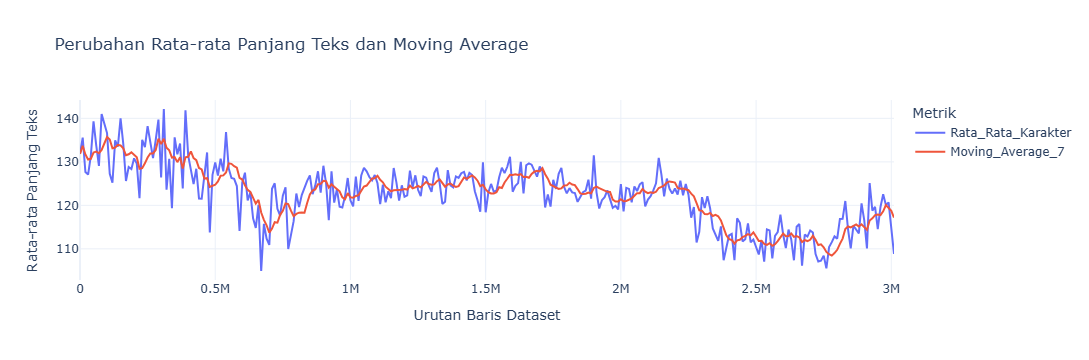

In [4]:
# ============================================================
# 2.2 VISUALISASI ROLLING MEAN
# ============================================================

rolling_pd = df_rolling.to_pandas()

fig_rolling = px.line(
    rolling_pd,
    x="Urutan_Baris",
    y=[
        "Rata_Rata_Karakter",
        "Moving_Average_7"
    ],
    title=(
        "Perubahan Rata-rata Panjang Teks "
        "dan Moving Average"
    ),
    labels={
        "Urutan_Baris": "Urutan Baris Dataset",
        "value": "Rata-rata Panjang Teks",
        "variable": "Metrik"
    }
)

fig_rolling.update_layout(
    template="plotly_white",
    hovermode="x unified"
)

fig_rolling.show()

In [5]:
# ============================================================
# 2.3 — DUCKDB WINDOW FUNCTIONS (PERBAIKAN OVERFLOW)
# ============================================================

import duckdb
import polars as pl

# Ambil sebagian data untuk demonstrasi window functions
SAMPLE_SIZE = min(100_000, df.height)

window_df = (
    df.head(SAMPLE_SIZE)
    .select([
        "Label",
        "Denomination",
        "Location",
        "Panjang_Karakter",
        "Jumlah_Kata"
    ])
    .with_row_index("Urutan_Baris")
)

# Ubah kolom numerik ke tipe yang aman untuk operasi aritmetika
window_df = window_df.with_columns([
    pl.col("Urutan_Baris").cast(pl.Int64),
    pl.col("Panjang_Karakter").cast(pl.Int64),
    pl.col("Jumlah_Kata").cast(pl.Int64)
])

con = duckdb.connect()

con.register("corpus_window", window_df.to_arrow())

query_window = """
SELECT
    Urutan_Baris,
    Label,
    Denomination,
    Location,
    Panjang_Karakter,
    Jumlah_Kata,

    -- Akumulasi panjang karakter
    SUM(CAST(Panjang_Karakter AS BIGINT)) OVER (
        ORDER BY Urutan_Baris
        ROWS BETWEEN UNBOUNDED PRECEDING AND CURRENT ROW
    ) AS Kumulatif_Karakter,

    -- Rata-rata panjang karakter pada 7 baris terakhir
    AVG(CAST(Panjang_Karakter AS DOUBLE)) OVER (
        ORDER BY Urutan_Baris
        ROWS BETWEEN 6 PRECEDING AND CURRENT ROW
    ) AS Rata_Rata_7_Baris,

    -- Panjang karakter pada baris sebelumnya
    LAG(CAST(Panjang_Karakter AS BIGINT), 1) OVER (
        ORDER BY Urutan_Baris
    ) AS Karakter_Sebelumnya,

    -- Perubahan panjang teks dibandingkan baris sebelumnya
    CAST(Panjang_Karakter AS BIGINT)
    - LAG(CAST(Panjang_Karakter AS BIGINT), 1) OVER (
        ORDER BY Urutan_Baris
    ) AS Perubahan_Karakter,

    -- Peringkat panjang teks dalam setiap label
    RANK() OVER (
        PARTITION BY Label
        ORDER BY Panjang_Karakter DESC
    ) AS Peringkat_Panjang_Teks

FROM corpus_window
ORDER BY Urutan_Baris
"""

window_result = con.execute(query_window).pl()

print("Window functions berhasil dijalankan!")
print(f"Jumlah baris hasil: {window_result.height:,}")
display(window_result.head(10))

con.close()

Window functions berhasil dijalankan!
Jumlah baris hasil: 100,000


Urutan_Baris,Label,Denomination,Location,Panjang_Karakter,Jumlah_Kata,Kumulatif_Karakter,Rata_Rata_7_Baris,Karakter_Sebelumnya,Perubahan_Karakter,Peringkat_Panjang_Teks
i64,str,str,str,i64,i64,"decimal[38,0]",f64,i64,i64,i64
0,"""Catholic""","""Katolisitas""","""National""",108,14,108,108.0,null,null,56087
1,"""Catholic""","""Katolisitas""","""National""",82,9,190,95.0,108,-26,73873
2,"""Catholic""","""Katolisitas""","""National""",29,5,219,73.0,82,-53,99650
3,"""Catholic""","""Katolisitas""","""National""",34,5,253,63.25,29,5,98820
4,"""Catholic""","""Katolisitas""","""National""",130,19,383,76.6,34,96,42633
5,"""Catholic""","""Katolisitas""","""National""",101,16,484,80.666667,130,-29,60716
6,"""Catholic""","""Katolisitas""","""National""",108,13,592,84.571429,101,7,56087
7,"""Catholic""","""Katolisitas""","""National""",92,13,684,82.285714,108,-16,66916
8,"""Catholic""","""Katolisitas""","""National""",97,12,781,84.428571,92,5,63516


In [6]:
# ============================================================
# 2.5 WINDOW FUNCTIONS BERDASARKAN LABEL
# ============================================================

con = duckdb.connect(database=":memory:")

con.register(
    "corpus_data",
    df.select([
        LABEL_COL,
        "Panjang_Karakter",
        "Jumlah_Kata"
    ]).to_arrow()
)

query_label = """
WITH label_summary AS (
    SELECT
        Label,
        COUNT(*) AS Jumlah_Dokumen,
        AVG(Panjang_Karakter) AS Rata_Rata_Karakter,
        AVG(Jumlah_Kata) AS Rata_Rata_Kata
    FROM corpus_data
    GROUP BY Label
)
SELECT
    Label,
    Jumlah_Dokumen,
    Rata_Rata_Karakter,
    Rata_Rata_Kata,

    SUM(Jumlah_Dokumen) OVER ()
        AS Total_Dokumen,

    ROUND(
        100.0 * Jumlah_Dokumen
        / SUM(Jumlah_Dokumen) OVER (),
        2
    ) AS Persentase_Dokumen,

    RANK() OVER (
        ORDER BY Rata_Rata_Karakter DESC
    ) AS Peringkat_Rata_Rata_Panjang

FROM label_summary
ORDER BY Jumlah_Dokumen DESC
"""

label_window = con.execute(query_label).pl()

con.close()

display(label_window)

Label,Jumlah_Dokumen,Rata_Rata_Karakter,Rata_Rata_Kata,Total_Dokumen,Persentase_Dokumen,Peringkat_Rata_Rata_Panjang
str,i64,f64,f64,"decimal[38,0]",f64,i64
"""Islam""",1455099,124.268134,17.212279,3012817,48.3,2
"""Catholic""",797131,127.271997,17.720301,3012817,26.46,1
"""Protestant""",760587,114.012647,16.166805,3012817,25.25,3


In [7]:
# ============================================================
# 2.6 RINGKASAN WINDOW FUNCTIONS
# ============================================================

summary_window = window_result.select([
    pl.col("Panjang_Karakter")
    .mean()
    .alias("Rata_Rata_Karakter"),

    pl.col("Panjang_Karakter")
    .median()
    .alias("Median_Karakter"),

    pl.col("Jumlah_Kata")
    .mean()
    .alias("Rata_Rata_Kata"),

    pl.col("Kumulatif_Karakter")
    .max()
    .alias("Total_Karakter_Sampel")
])

display(summary_window)

print("\nAnalisis selesai.")
print(f"Jumlah baris sampel: {window_result.height:,}")
print("Metode: Polars Rolling Mean dan DuckDB Window Functions")

Rata_Rata_Karakter,Median_Karakter,Rata_Rata_Kata,Total_Karakter_Sampel
f64,f64,f64,"decimal[38,0]"
133.5625,118.0,18.60338,13356250



Analisis selesai.
Jumlah baris sampel: 100,000
Metode: Polars Rolling Mean dan DuckDB Window Functions


## Bagian 3: Minimal 6 Visualisasi Interaktif (Plotly / Altair)

Bangun minimal 6 visualisasi interaktif yang mencakup:
- Visualisasi 1: Tren deret waktu (Line chart dengan range slider)
- Visualisasi 2: Distribusi variabel utama (Box plot / Histogram / Violin plot)
- Visualisasi 3: Korelasi antar-variabel numerik (Heatmap / Scatter plot sampling)
- Visualisasi 4: Komposisi kategori utama (Bar chart / Treemap)
- Visualisasi 5: Analisis siklus musiman / perbandingan kelompok
- Visualisasi 6: Pola spasial atau korelasi multi-dimensi

In [8]:
# ============================================================
# BAGIAN 3 — DASHBOARD VISUALISASI INTERAKTIF
# Indonesian Religious Corpus
# ============================================================

import polars as pl
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display, HTML

# ------------------------------------------------------------
# 1. KONFIGURASI
# ------------------------------------------------------------

SAMPLE_SIZE = 50_000
MAX_CATEGORY = 15
RANDOM_SEED = 42

# Tema dashboard
TEMA = "plotly_dark"

WARNA = {
    "cyan": "#22D3EE",
    "ungu": "#A78BFA",
    "hijau": "#34D399",
    "oranye": "#FB923C",
    "merah": "#FB7185",
    "biru": "#60A5FA",
    "kuning": "#FBBF24",
    "putih": "#F8FAFC",
    "abu": "#94A3B8"
}

# ------------------------------------------------------------
# 2. VALIDASI DATA
# ------------------------------------------------------------

kolom_wajib = [
    "Label",
    "Denomination",
    "Location",
    "Sentence_Unit"
]

kolom_hilang = [c for c in kolom_wajib if c not in df.columns]

if kolom_hilang:
    raise ValueError(
        f"Kolom berikut tidak ditemukan dalam df: {kolom_hilang}"
    )

# ------------------------------------------------------------
# 3. FEATURE ENGINEERING
# ------------------------------------------------------------

df = df.with_columns([
    pl.col("Label").fill_null("Tidak diketahui"),
    pl.col("Denomination").fill_null("Tidak diketahui"),
    pl.col("Location").fill_null("Tidak diketahui"),
    pl.col("Sentence_Unit").fill_null("")
])

# Buat fitur hanya jika belum tersedia
fitur_baru = []

if "Panjang_Karakter" not in df.columns:
    fitur_baru.append(
        pl.col("Sentence_Unit")
        .str.len_chars()
        .alias("Panjang_Karakter")
    )

if "Jumlah_Kata" not in df.columns:
    fitur_baru.append(
        pl.col("Sentence_Unit")
        .str.count_matches(r"\S+")
        .alias("Jumlah_Kata")
    )

if fitur_baru:
    df = df.with_columns(fitur_baru)

df = df.with_columns([
    pl.col("Panjang_Karakter").cast(pl.Int64),
    pl.col("Jumlah_Kata").cast(pl.Int64)
])

# Dataset untuk visualisasi distribusi
df_analisis = df.filter(
    (pl.col("Panjang_Karakter") > 0)
    & (pl.col("Jumlah_Kata") > 0)
)

# Sampel acak untuk grafik yang menggunakan data individual
n_sample = min(SAMPLE_SIZE, df_analisis.height)

df_sample = df_analisis.sample(
    n=n_sample,
    seed=RANDOM_SEED
).to_pandas()

# Data ringkasan kategori
df_label = (
    df.group_by("Label")
    .agg([
        pl.len().alias("Jumlah_Data"),
        pl.col("Panjang_Karakter").mean().alias("Rata_Karakter"),
        pl.col("Jumlah_Kata").mean().alias("Rata_Kata")
    ])
    .sort("Jumlah_Data", descending=True)
    .to_pandas()
)

df_denom = (
    df.group_by("Denomination")
    .agg(pl.len().alias("Jumlah_Data"))
    .sort("Jumlah_Data", descending=True)
    .to_pandas()
)

df_lokasi = (
    df.group_by("Location")
    .agg(pl.len().alias("Jumlah_Data"))
    .sort("Jumlah_Data", descending=True)
    .to_pandas()
)

# ------------------------------------------------------------
# 4. HEADER DASHBOARD
# ------------------------------------------------------------

jumlah_data = df.height
jumlah_label = df["Label"].n_unique()
jumlah_denom = df["Denomination"].n_unique()
jumlah_lokasi = df["Location"].n_unique()

display(HTML(f"""
<div style="
    background:linear-gradient(135deg,#0F172A,#1E293B,#312E81);
    padding:28px;
    border-radius:18px;
    color:#F8FAFC;
    font-family:Arial,sans-serif;
    margin:10px 0 20px 0;
    border:1px solid #334155;
">
    <div style="font-size:13px;color:#67E8F9;letter-spacing:3px;">
        BIG DATA ANALYTICS · MILESTONE 3
    </div>
    <h1 style="margin:12px 0;font-size:30px;">
        Indonesian Religious Corpus
    </h1>
    <p style="color:#CBD5E1;font-size:14px;">
        Interactive Data Exploration Dashboard
    </p>
    <hr style="border-color:#475569;">
    <div style="display:flex;flex-wrap:wrap;gap:35px;">
        <div>
            <div style="color:#94A3B8;font-size:12px;">TOTAL BARIS</div>
            <div style="font-size:26px;font-weight:bold;">
                {jumlah_data:,}
            </div>
        </div>
        <div>
            <div style="color:#94A3B8;font-size:12px;">JUMLAH LABEL</div>
            <div style="font-size:26px;font-weight:bold;">
                {jumlah_label:,}
            </div>
        </div>
        <div>
            <div style="color:#94A3B8;font-size:12px;">DENOMINASI</div>
            <div style="font-size:26px;font-weight:bold;">
                {jumlah_denom:,}
            </div>
        </div>
        <div>
            <div style="color:#94A3B8;font-size:12px;">LOKASI</div>
            <div style="font-size:26px;font-weight:bold;">
                {jumlah_lokasi:,}
            </div>
        </div>
    </div>
</div>
"""))

print("Persiapan dashboard selesai.")
print(f"Total data              : {jumlah_data:,}")
print(f"Data sampel untuk grafik: {len(df_sample):,}")
print("Silakan lanjut ke enam visualisasi.")

Persiapan dashboard selesai.
Total data              : 3,012,817
Data sampel untuk grafik: 50,000
Silakan lanjut ke enam visualisasi.


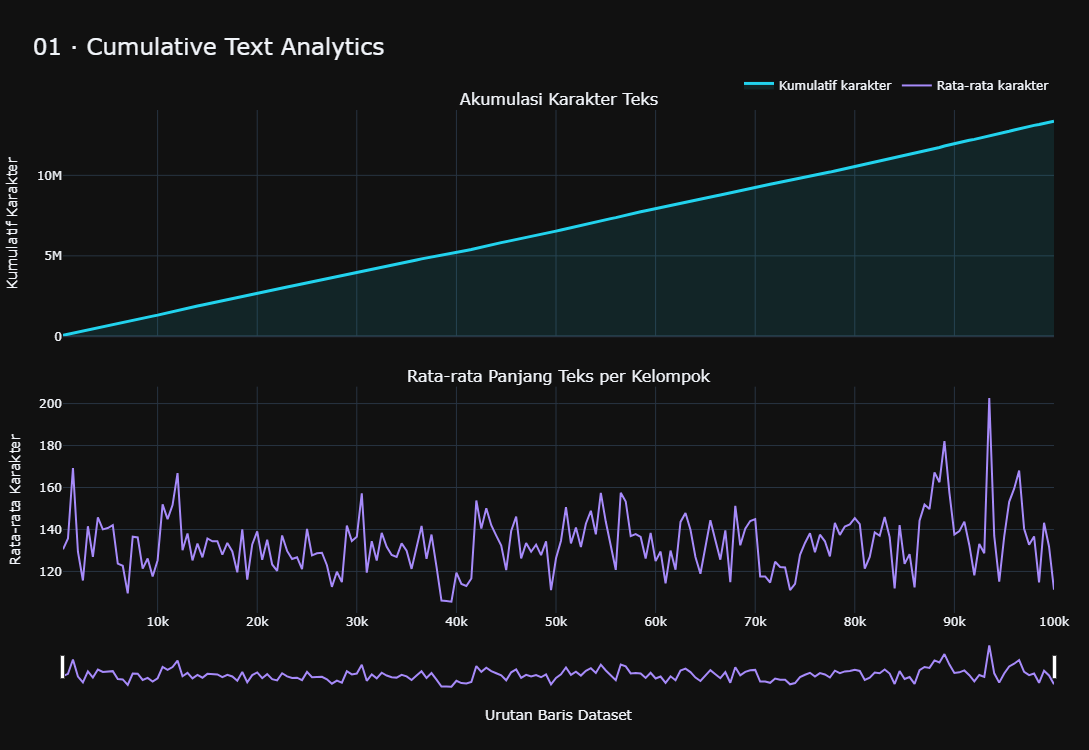

In [9]:
# ============================================================
# VISUALISASI 1 — INTERACTIVE CUMULATIVE TREND
# ============================================================

# Gunakan urutan data asli untuk mempertahankan urutan baris
df_trend_source = (
    df.head(min(100_000, df.height))
    .select(["Panjang_Karakter"])
    .with_row_index("Urutan")
    .with_columns([
        (pl.col("Urutan") + 1).alias("Urutan"),
        pl.col("Panjang_Karakter").cast(pl.Float64)
    ])
)

# Agregasi per 500 baris
df_trend = (
    df_trend_source
    .with_columns(
        ((pl.col("Urutan") - 1) // 500).alias("Kelompok")
    )
    .group_by("Kelompok")
    .agg([
        pl.col("Panjang_Karakter").mean().alias("Rata_Rata"),
        pl.col("Panjang_Karakter").sum().alias("Total_Karakter"),
        pl.col("Urutan").max().alias("Urutan_Akhir")
    ])
    .sort("Kelompok")
    .with_columns(
        pl.col("Total_Karakter").cum_sum().alias("Kumulatif")
    )
    .to_pandas()
)

fig1 = make_subplots(
    rows=2,
    cols=1,
    shared_xaxes=True,
    vertical_spacing=0.10,
    subplot_titles=(
        "Akumulasi Karakter Teks",
        "Rata-rata Panjang Teks per Kelompok"
    )
)

fig1.add_trace(
    go.Scatter(
        x=df_trend["Urutan_Akhir"],
        y=df_trend["Kumulatif"],
        mode="lines",
        name="Kumulatif karakter",
        line=dict(color=WARNA["cyan"], width=3),
        fill="tozeroy",
        fillcolor="rgba(34,211,238,0.10)",
        hovertemplate=(
            "Baris: %{x:,.0f}<br>"
            "Kumulatif: %{y:,.0f}<extra></extra>"
        )
    ),
    row=1,
    col=1
)

fig1.add_trace(
    go.Scatter(
        x=df_trend["Urutan_Akhir"],
        y=df_trend["Rata_Rata"],
        mode="lines",
        name="Rata-rata karakter",
        line=dict(color=WARNA["ungu"], width=2),
        hovertemplate=(
            "Baris: %{x:,.0f}<br>"
            "Rata-rata karakter: %{y:.2f}<extra></extra>"
        )
    ),
    row=2,
    col=1
)

fig1.update_layout(
    title=dict(
        text="01 · Cumulative Text Analytics",
        x=0.03,
        font=dict(size=23)
    ),
    template=TEMA,
    height=750,
    hovermode="x unified",
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),
    margin=dict(l=60, r=35, t=110, b=60)
)

fig1.update_xaxes(
    title_text="Urutan Baris Dataset",
    rangeslider=dict(visible=True, thickness=0.08),
    row=2,
    col=1
)

fig1.update_yaxes(title_text="Kumulatif Karakter", row=1, col=1)
fig1.update_yaxes(title_text="Rata-rata Karakter", row=2, col=1)

fig1.show()

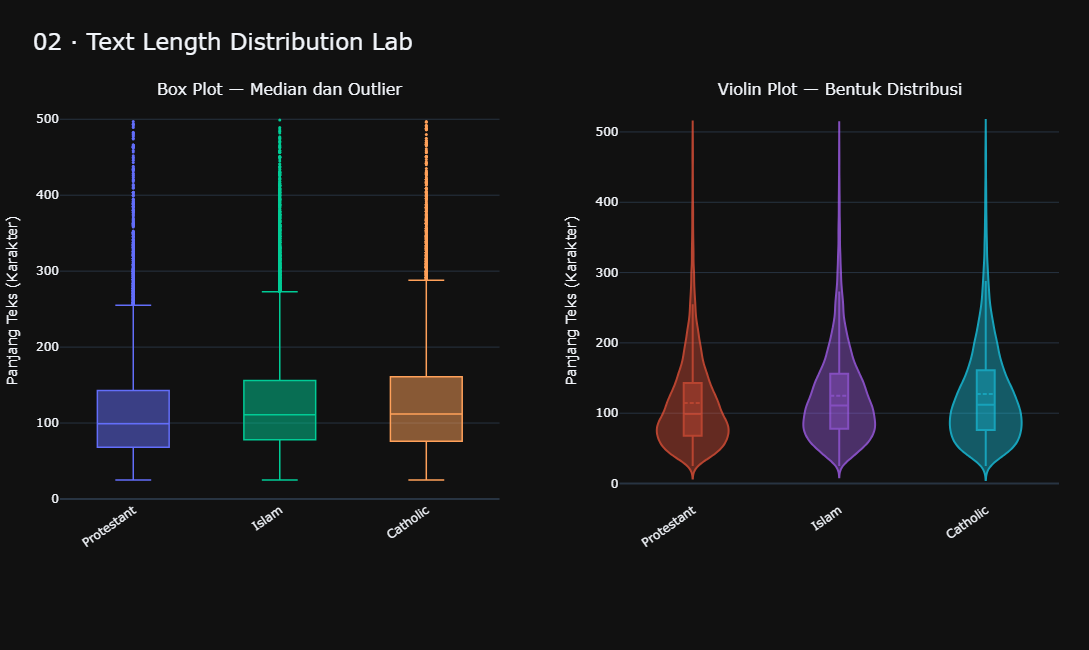

In [10]:
# ============================================================
# VISUALISASI 2 — DISTRIBUTION LAB
# ============================================================

# Pilih label dengan jumlah sampel terbesar
top_labels = (
    df_label
    .nlargest(10, "Jumlah_Data")["Label"]
    .tolist()
)

df_dist = df_sample[
    df_sample["Label"].isin(top_labels)
].copy()

urutan_label = (
    df_dist.groupby("Label")["Panjang_Karakter"]
    .median()
    .sort_values()
    .index.tolist()
)

fig2 = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=(
        "Box Plot — Median dan Outlier",
        "Violin Plot — Bentuk Distribusi"
    ),
    horizontal_spacing=0.12
)

for label in urutan_label:
    data_label = df_dist[df_dist["Label"] == label]

    fig2.add_trace(
        go.Box(
            y=data_label["Panjang_Karakter"],
            name=label,
            boxpoints="outliers",
            marker=dict(size=3),
            line=dict(width=1.5),
            showlegend=False,
            hovertemplate=(
                "Label: " + str(label) +
                "<br>Panjang karakter: %{y}<extra></extra>"
            )
        ),
        row=1,
        col=1
    )

    fig2.add_trace(
        go.Violin(
            y=data_label["Panjang_Karakter"],
            name=label,
            box_visible=True,
            meanline_visible=True,
            points=False,
            opacity=0.75,
            showlegend=False,
            hovertemplate=(
                "Label: " + str(label) +
                "<br>Panjang karakter: %{y}<extra></extra>"
            )
        ),
        row=1,
        col=2
    )

fig2.update_layout(
    title=dict(
        text="02 · Text Length Distribution Lab",
        x=0.03,
        font=dict(size=23)
    ),
    template=TEMA,
    height=650,
    margin=dict(l=60, r=30, t=100, b=150)
)

fig2.update_yaxes(title_text="Panjang Teks (Karakter)", row=1, col=1)
fig2.update_yaxes(title_text="Panjang Teks (Karakter)", row=1, col=2)

fig2.update_xaxes(
    tickangle=-35,
    categoryorder="array",
    categoryarray=urutan_label,
    row=1,
    col=1
)

fig2.update_xaxes(
    tickangle=-35,
    categoryorder="array",
    categoryarray=urutan_label,
    row=1,
    col=2
)

fig2.show()

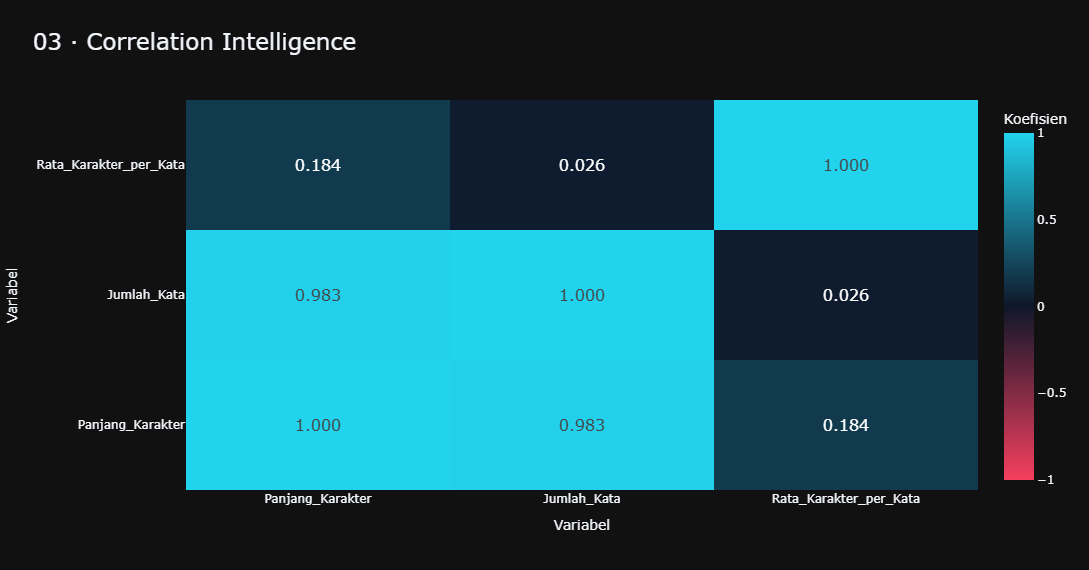

In [11]:
# ============================================================
# VISUALISASI 3 — CORRELATION INTELLIGENCE
# ============================================================

df_corr = df_sample[
    ["Panjang_Karakter", "Jumlah_Kata"]
].copy()

df_corr["Rata_Karakter_per_Kata"] = (
    df_corr["Panjang_Karakter"]
    / df_corr["Jumlah_Kata"].replace(0, np.nan)
)

df_corr = df_corr.replace(
    [np.inf, -np.inf],
    np.nan
).dropna()

corr_matrix = df_corr.corr(method="pearson")

fig3 = go.Figure(
    data=go.Heatmap(
        z=corr_matrix.values,
        x=corr_matrix.columns,
        y=corr_matrix.index,
        colorscale=[
            [0.0, "#F43F5E"],
            [0.5, "#0F172A"],
            [1.0, "#22D3EE"]
        ],
        zmin=-1,
        zmax=1,
        text=np.round(corr_matrix.values, 3),
        texttemplate="%{text:.3f}",
        textfont=dict(size=16),
        colorbar=dict(
            title="Koefisien",
            ticksuffix=""
        ),
        hovertemplate=(
            "Variabel X: %{x}<br>"
            "Variabel Y: %{y}<br>"
            "Korelasi: %{z:.3f}<extra></extra>"
        )
    )
)

fig3.update_layout(
    title=dict(
        text="03 · Correlation Intelligence",
        x=0.03,
        font=dict(size=23)
    ),
    template=TEMA,
    height=570,
    xaxis_title="Variabel",
    yaxis_title="Variabel",
    margin=dict(l=100, r=50, t=100, b=80)
)

fig3.show()

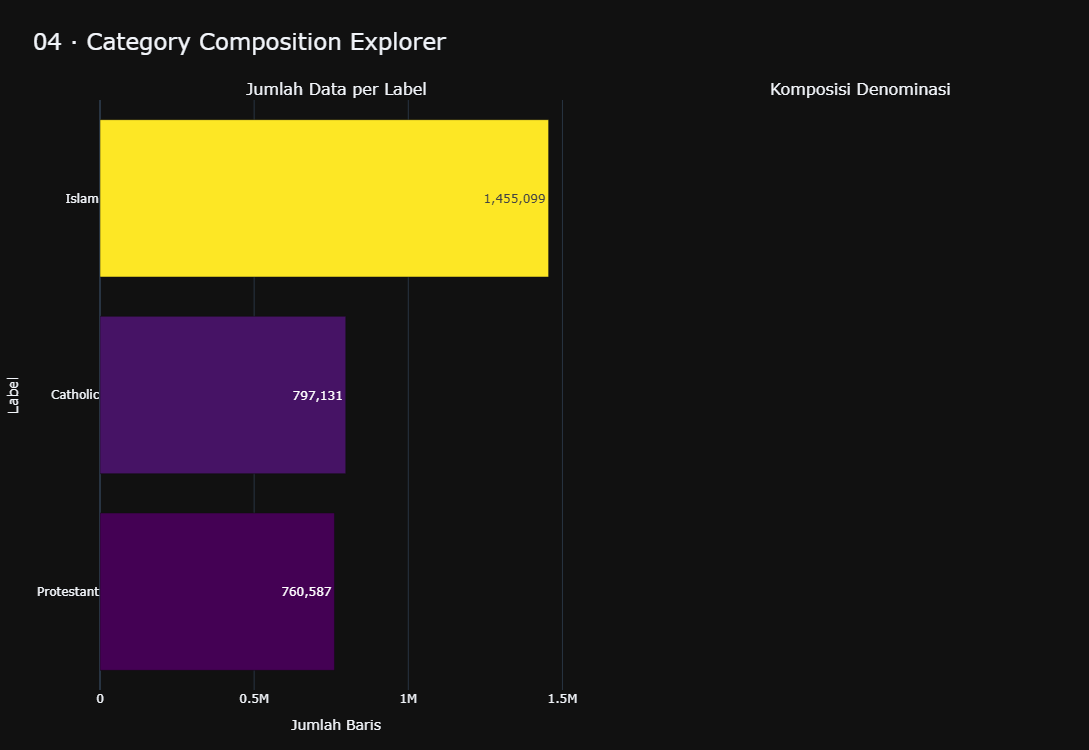

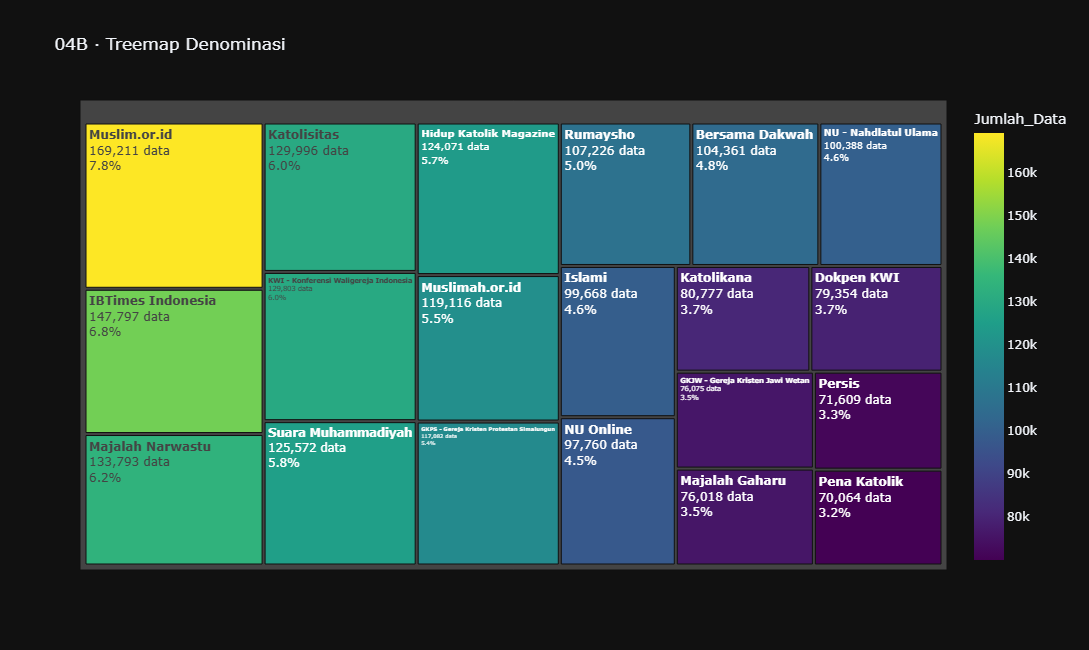

In [12]:
# ============================================================
# VISUALISASI 4 — CATEGORY COMPOSITION EXPLORER
# ============================================================

df_label_plot = (
    df_label
    .sort_values("Jumlah_Data", ascending=False)
    .copy()
)

df_denom_plot = (
    df_denom
    .sort_values("Jumlah_Data", ascending=False)
    .head(20)
    .copy()
)

fig4 = make_subplots(
    rows=1,
    cols=2,
    specs=[[{"type": "bar"}, {"type": "treemap"}]],
    subplot_titles=(
        "Jumlah Data per Label",
        "Komposisi Denominasi"
    ),
    column_widths=[0.55, 0.45]
)

fig4.add_trace(
    go.Bar(
        x=df_label_plot["Jumlah_Data"],
        y=df_label_plot["Label"],
        orientation="h",
        marker=dict(
            color=df_label_plot["Jumlah_Data"],
            colorscale="Viridis",
            showscale=False
        ),
        text=df_label_plot["Jumlah_Data"].map(lambda x: f"{x:,}"),
        textposition="auto",
        name="Jumlah data",
        hovertemplate=(
            "Label: %{y}<br>"
            "Jumlah data: %{x:,}<extra></extra>"
        )
    ),
    row=1,
    col=1
)

fig4.update_layout(
    title=dict(
        text="04 · Category Composition Explorer",
        x=0.03,
        font=dict(size=23)
    ),
    template=TEMA,
    height=750,
    showlegend=False,
    margin=dict(l=60, r=35, t=100, b=60)
)

fig4.update_yaxes(
    title_text="Label",
    autorange="reversed",
    row=1,
    col=1
)

fig4.update_xaxes(
    title_text="Jumlah Baris",
    row=1,
    col=1
)

# Treemap denominasi
fig4b = px.treemap(
    df_denom_plot,
    path=["Denomination"],
    values="Jumlah_Data",
    color="Jumlah_Data",
    color_continuous_scale="Viridis",
    title="04B · Treemap Denominasi",
    hover_data={"Jumlah_Data": ":,"}
)

fig4b.update_traces(
    texttemplate="<b>%{label}</b><br>%{value:,} data<br>%{percentRoot:.1%}",
    hovertemplate=(
        "Denominasi: %{label}<br>"
        "Jumlah data: %{value:,}<br>"
        "Proporsi: %{percentRoot:.2%}<extra></extra>"
    )
)

fig4b.update_layout(
    template=TEMA,
    height=650
)

fig4.show()
fig4b.show()

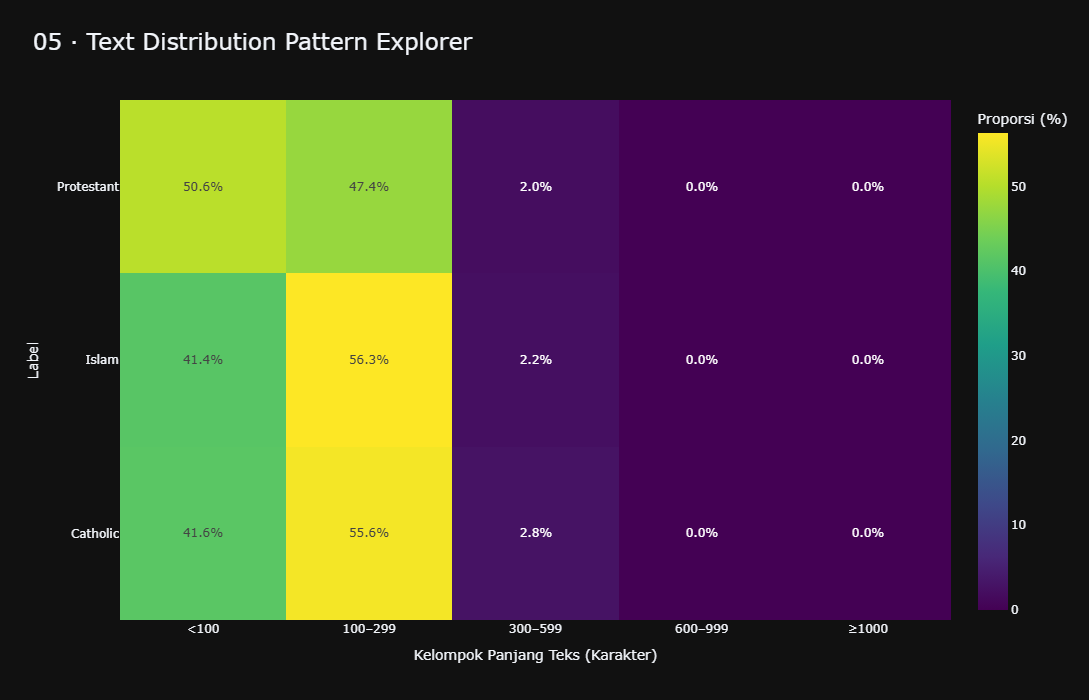

In [13]:
# ============================================================
# VISUALISASI 5 — DISTRIBUTION PATTERN HEATMAP
# ============================================================

df_pattern = df_sample.copy()

bins = [0, 100, 300, 600, 1000, np.inf]
labels_bins = [
    "<100",
    "100–299",
    "300–599",
    "600–999",
    "≥1000"
]

df_pattern["Kelompok_Panjang"] = pd.cut(
    df_pattern["Panjang_Karakter"],
    bins=bins,
    labels=labels_bins,
    right=False
)

# Ambil 15 label terbesar berdasarkan jumlah data
top15_labels = (
    df_label
    .nlargest(15, "Jumlah_Data")["Label"]
    .tolist()
)

df_pattern = df_pattern[
    df_pattern["Label"].isin(top15_labels)
]

pivot_pattern = pd.crosstab(
    df_pattern["Label"],
    df_pattern["Kelompok_Panjang"]
)

# Susun kolom sesuai urutan interval
pivot_pattern = pivot_pattern.reindex(
    columns=labels_bins,
    fill_value=0
)

# Normalisasi per label untuk membandingkan proporsi
pivot_proporsi = pivot_pattern.div(
    pivot_pattern.sum(axis=1).replace(0, np.nan),
    axis=0
).fillna(0) * 100

fig5 = go.Figure(
    data=go.Heatmap(
        z=pivot_proporsi.values,
        x=pivot_proporsi.columns.astype(str),
        y=pivot_proporsi.index.astype(str),
        colorscale="Viridis",
        colorbar=dict(title="Proporsi (%)"),
        text=np.round(pivot_proporsi.values, 1),
        texttemplate="%{text:.1f}%",
        hovertemplate=(
            "Label: %{y}<br>"
            "Kelompok panjang: %{x}<br>"
            "Proporsi: %{z:.1f}%<extra></extra>"
        )
    )
)

fig5.update_layout(
    title=dict(
        text="05 · Text Distribution Pattern Explorer",
        x=0.03,
        font=dict(size=23)
    ),
    template=TEMA,
    height=700,
    xaxis_title="Kelompok Panjang Teks (Karakter)",
    yaxis_title="Label",
    margin=dict(l=120, r=50, t=100, b=80)
)

fig5.show()

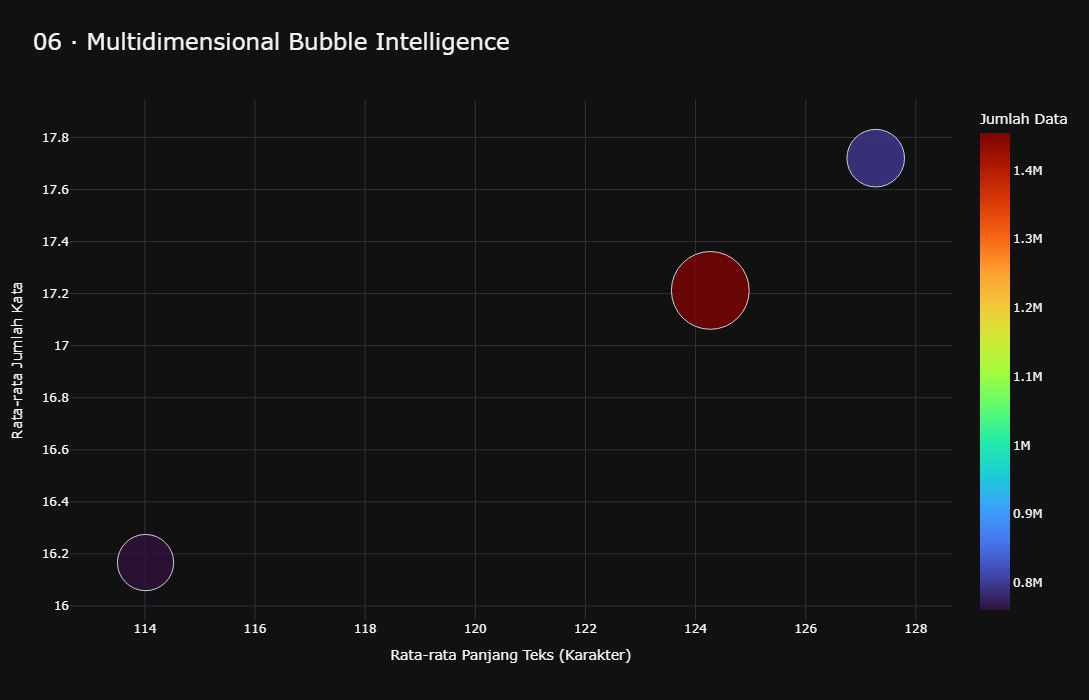

In [14]:
# ============================================================
# VISUALISASI 6 — MULTIDIMENSIONAL BUBBLE INTELLIGENCE
# ============================================================

df_multi = df_label.copy()

df_multi = df_multi.replace(
    [np.inf, -np.inf],
    np.nan
).dropna(
    subset=["Rata_Karakter", "Rata_Kata"]
)

# Ukuran gelembung memakai jumlah data
fig6 = px.scatter(
    df_multi,
    x="Rata_Karakter",
    y="Rata_Kata",
    size="Jumlah_Data",
    color="Jumlah_Data",
    hover_name="Label",
    size_max=55,
    color_continuous_scale="Turbo",
    custom_data=["Label", "Jumlah_Data"],
    title="06 · Multidimensional Bubble Intelligence",
    labels={
        "Rata_Karakter": "Rata-rata Panjang Teks (Karakter)",
        "Rata_Kata": "Rata-rata Jumlah Kata",
        "Jumlah_Data": "Jumlah Baris"
    },
    hover_data={
        "Jumlah_Data": ":,",
        "Rata_Karakter": ":.2f",
        "Rata_Kata": ":.2f"
    }
)

fig6.update_traces(
    marker=dict(
        opacity=0.82,
        line=dict(width=1, color="#F8FAFC")
    )
)

fig6.update_layout(
    template=TEMA,
    height=700,
    title=dict(
        x=0.03,
        font=dict(size=23)
    ),
    coloraxis_colorbar=dict(
        title="Jumlah Data"
    ),
    margin=dict(l=70, r=50, t=100, b=80)
)

fig6.show()

## Bagian 4: Rumusan 5 Insight Analitik Utama

Berdasarkan hasil analisis *window functions* dan enam visualisasi interaktif pada *Indonesian Religious Corpus*, terdapat lima insight utama. Insight berikut disesuaikan dengan kolom dan keluaran yang benar-benar tersedia pada notebook, yaitu karakteristik teks, distribusi kategori, korelasi fitur numerik, serta perbandingan karakteristik antarkategori.

### 1. Insight 1 — Akumulasi Karakter dan Perubahan Panjang Teks

Visualisasi **Cumulative Text Analytics** memperlihatkan akumulasi jumlah karakter dan perubahan rata-rata panjang teks berdasarkan urutan baris dataset. Pada analisis *rolling mean*, rata-rata panjang teks per blok 10.000 baris pada sepuluh blok awal berada di kisaran sekitar 127–141 karakter. Nilai ini menunjukkan bahwa panjang teks bervariasi di antara blok data yang diamati.

Namun, dataset tidak memiliki kolom tanggal atau *timestamp* yang valid. Karena itu, urutan baris tidak dapat dianggap sebagai urutan waktu. Grafik ini hanya menunjukkan pola berdasarkan urutan penyimpanan data, bukan tren temporal, perubahan dari waktu ke waktu, atau pola musiman. Hasilnya juga dapat dipengaruhi oleh urutan penggabungan sumber data.

### 2. Insight 2 — Distribusi Panjang Teks dan Potensi Pencilan

Visualisasi **Text Length Distribution Lab** menggabungkan *box plot* dan *violin plot* untuk membandingkan distribusi panjang teks pada label-label dengan jumlah data terbesar. Kedua grafik membantu melihat median, rentang sebaran, bentuk distribusi, serta titik yang berpotensi menjadi pencilan (*outlier*).

Pencilan panjang teks perlu ditinjau berdasarkan isi teks dan konteks sumbernya. Teks yang jauh lebih pendek atau lebih panjang daripada mayoritas data tidak otomatis merupakan kesalahan; teks tersebut dapat berupa kutipan singkat, kalimat penjelas, atau bagian teks yang memang lebih panjang. Oleh sebab itu, pencilan sebaiknya diperiksa sebelum diputuskan untuk dihapus atau dipertahankan.

### 3. Insight 3 — Hubungan Panjang Karakter, Jumlah Kata, dan Rata-rata Karakter per Kata

Visualisasi **Correlation Intelligence** menampilkan korelasi Pearson antara `Panjang_Karakter`, `Jumlah_Kata`, dan `Rata_Karakter_per_Kata` pada sampel data. Ketiga variabel tersebut menggambarkan aspek panjang teks yang saling berkaitan, tetapi mengukur karakteristik yang berbeda.

Secara interpretatif, teks dengan jumlah kata lebih banyak cenderung memiliki jumlah karakter yang lebih besar. Sementara itu, `Rata_Karakter_per_Kata` dapat membantu membedakan teks yang tersusun dari kata-kata relatif pendek dan relatif panjang. Kekuatan hubungan setiap pasangan variabel harus dibaca dari angka pada *heatmap* yang dihasilkan, bukan disimpulkan hanya dari warna. Korelasi juga tidak membuktikan hubungan sebab-akibat.

### 4. Insight 4 — Komposisi Label dan Perbedaan Karakteristik Antarkategori

Visualisasi **Category Composition Explorer** memperlihatkan bahwa distribusi label pada dataset tidak seimbang. Berdasarkan ringkasan *window functions*, label **Islam** berjumlah 1.455.099 data (sekitar 48,30%), **Catholic** sebanyak 797.131 data (sekitar 26,46%), dan **Protestant** sebanyak 760.587 data (sekitar 25,25%), dari total 3.012.817 baris. Dengan demikian, Islam merupakan label dengan jumlah data terbesar dalam korpus.

Rata-rata panjang teks pada ringkasan tersebut adalah sekitar 124,27 karakter untuk Islam, 127,27 karakter untuk Catholic, dan 114,01 karakter untuk Protestant. Rata-rata jumlah katanya masing-masing sekitar 17,21, 17,72, dan 16,17 kata. Angka ini menunjukkan adanya perbedaan karakteristik panjang teks antarkategori, tetapi belum cukup untuk menyimpulkan perbedaan isi atau kualitas teks. Treemap denominasi membantu melihat komposisi denominasi yang ditampilkan, sedangkan **Multidimensional Bubble Intelligence** membandingkan rata-rata panjang karakter, rata-rata jumlah kata, dan jumlah data per label secara bersamaan.

### 5. Insight 5 — Pola Kelompok Panjang Teks dan Rekomendasi Pengolahan

Visualisasi **Text Distribution Pattern Explorer** membandingkan proporsi kelompok panjang teks (`<100`, `100–299`, `300–599`, `600–999`, dan `≥1000` karakter) pada label-label dengan jumlah data terbesar. Visualisasi ini merupakan analisis distribusi kelompok panjang teks, bukan analisis musiman. Perbandingan proporsi membantu melihat apakah kategori tertentu lebih banyak berisi teks pendek atau panjang.

Berdasarkan keseluruhan visualisasi, beberapa langkah lanjutan yang disarankan adalah:
1. Memeriksa keseimbangan jumlah data antarlabel dan denominasi sebelum melakukan analisis lanjutan.
2. Meninjau pencilan panjang teks berdasarkan isi dan sumbernya, bukan langsung menghapusnya.
3. Memakai korelasi numerik sebagai informasi eksploratif ketika memilih fitur untuk pemrosesan teks berikutnya.
4. Membandingkan distribusi panjang teks antarlabel dengan memperhatikan perbedaan jumlah sampel.
5. Jika analisis temporal atau musiman diwajibkan, memperoleh sumber data yang memiliki tanggal atau *timestamp* valid. Jangan menganggap urutan baris sebagai waktu.

### Kesimpulan

Enam visualisasi interaktif memberikan sudut pandang yang saling melengkapi terhadap korpus: akumulasi karakter dan rata-rata panjang teks berdasarkan urutan baris, distribusi panjang teks, korelasi fitur numerik, komposisi label dan denominasi, proporsi kelompok panjang teks, serta perbandingan multidimensi antarkategori. Hasil yang sudah terukur menunjukkan bahwa label Islam merupakan label terbesar dan bahwa rata-rata panjang teks berbeda antarkategori.

Interpretasi perlu tetap memperhatikan keterbatasan dataset. Karena tidak tersedia tanggal yang valid, visualisasi berbasis urutan baris tidak dapat digunakan untuk menyatakan tren waktu atau pola musiman. Selain itu, grafik distribusi dan korelasi dibuat menggunakan sampel untuk menjaga performa, sehingga hasilnya sebaiknya dipahami sebagai eksplorasi data dan tidak langsung ditafsirkan sebagai hubungan sebab-akibat.
